In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

PROJECT_DIR = "/content/drive/MyDrive/OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime"

print(os.listdir(PROJECT_DIR))

['requirements.txt', 'Proposal_OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime.docx', 'data', 'report', 'sql', 'Notebook_A_OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime.ipynb', 'Notebook_B_OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime.ipynb']


In [3]:
from google.colab import drive
import os, json, glob, re

drive.mount('/content/drive')
PROJECT_DIR = "/content/drive/MyDrive/OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime"
os.chdir(PROJECT_DIR)
os.makedirs("sql", exist_ok=True)

# Tự tạo sql/queries.sql từ Notebook A nếu chưa có
if not os.path.exists("sql/queries.sql"):
    nb_a = glob.glob("Notebook_A_*.ipynb")[0]
    for c in json.load(open(nb_a, encoding="utf-8"))["cells"]:
        src = "".join(c["source"])
        if c["cell_type"] == "code" and src.startswith('SQL = r"""'):
            sql = re.search(r'SQL = r"""(.*?)"""', src, re.S).group(1)
            with open("sql/queries.sql", "w", encoding="utf-8") as f:
                f.write(sql)
            break

print("Working dir     :", os.getcwd())
print("sql/queries.sql :", os.path.exists("sql/queries.sql"))
print("dengue.parquet  :", os.path.exists("data/processed/dengue.parquet"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working dir     : /content/drive/MyDrive/OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime
sql/queries.sql : True
dengue.parquet  : True


# Notebook B: chia dữ liệu, mô hình và câu hỏi thứ ba

**Đề tài:** Thời gian báo trước của cảnh báo bùng phát sốt xuất huyết trong năm dịch 2024 cho các đô thị Brazil đã thấy và chưa thấy, với số cảnh báo mỗi tuần có hạn

**Sinh viên B** chạy sau khi Notebook A đã tạo file parquet, `sql/queries.sql` và `manifest.json`. Notebook này không cần kernel của Notebook A.

## Kiểm tra bàn giao

- **Làm gì:** đọc manifest và so mã băm của file parquet.
- **Vì sao:** bảo đảm hai notebook dùng đúng cùng một dữ liệu.
- **Kiểm tra:** ô in `handover ok`.

In [4]:
import os

PROJECT_DIR = "/content/drive/MyDrive/OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime"

os.chdir(PROJECT_DIR)

print("Current working directory:")
print(os.getcwd())

print("\nProcessed files:")
print(os.listdir("data/processed"))

Current working directory:
/content/drive/MyDrive/OnGoingAssessment2_ACDSA_Dengue_OutbreakLeadTime

Processed files:
['dengue.parquet', 'manifest.json']


In [5]:
# run once per machine, then comment out
# %pip install pandas numpy duckdb pyarrow scikit-learn lightgbm xgboost matplotlib scipy
import os, json, hashlib, numpy as np, pandas as pd, warnings
warnings.filterwarnings('ignore')
m = json.load(open('data/processed/manifest.json'))
assert hashlib.md5(open(m['file'], 'rb').read()).hexdigest() == m['md5'], 'parquet differs from the manifest, rerun Notebook A'
os.makedirs('report', exist_ok=True); print('handover ok', m['rows'], 'rows')

handover ok 229600 rows


## Bước 4. Bảng đặc trưng và chia dữ liệu

- **Làm gì:** chạy lại `sql/queries.sql`, lấy bảng `feat`, chia tập huấn luyện và kiểm thử theo giao thức của đề tài.
- **Vì sao:** cách chia quyết định con số có đáng tin hay không; dòng `assert` là phép kiểm tra rò rỉ.
- **Kiểm tra:** ghi số dòng hai tập và số đặc trưng vào bảng mô tả thực nghiệm.

In [6]:
# Step 4: forward split: years up to 2022 for training, 2023 for calibration, the 2024 epidemic year for test; main horizon 4 weeks
import duckdb
con = duckdb.connect(); con.execute(open('sql/queries.sql').read())
feat = con.execute("SELECT * FROM feat ORDER BY ibge, week_start").df()
X_cols = ['l0', 'l1', 'l2', 'l3', 'l52', 'mean4', 'growth', 'state_log', 'thr_log', 'woy_sin', 'woy_cos']
H0 = 4; TARGET = 'y%d' % H0
part = lambda lo, hi: feat[(feat.year >= lo) & (feat.year <= hi)]
train, calib, test = part(2015, 2022), part(2023, 2023), part(2024, 2024)
N_TRAIN = min(60_000, len(train)); train = train.sample(N_TRAIN, random_state=0)       # cap keeps ten models affordable
X_tr, y_tr, X_te, y_te = train[X_cols], train[TARGET], test[X_cols], test[TARGET]
assert train.week_start.max() < calib.week_start.min() < test.week_start.min()         # leakage check
print(len(train), len(calib), len(test), len(X_cols), 'features', 'outbreak share train', round(y_tr.mean(), 3), 'test', round(y_te.mean(), 3))

60000 21200 17200 11 features outbreak share train 0.226 test 0.51


## Bước 4b. Hiểu tập huấn luyện và tập kiểm thử

Ba ô dưới đây kiểm tra hai tập có giống nhau không và đặc trưng nào mạnh nhất, trước khi huấn luyện bất kỳ mô hình nào.

### 4b.1 Mục tiêu ở hai tập

- **Làm gì:** so phân phối của mục tiêu giữa tập huấn luyện và tập kiểm thử.
- **Vì sao:** hai phân phối lệch nhau giải thích vì sao mô hình cây ngoại suy kém.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [7]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

import matplotlib.pyplot as plt
def nice(v, label):                                     # readable numbers on the bars
    v = np.asarray(v, dtype=float); m = np.nanmax(np.abs(v))
    return (v / 1e6, label + ' (million)', '{:.2f}') if m >= 1e6 else (v / 1e3, label + ' (thousand)', '{:.1f}') if m >= 1e4 else (v, label, '{:.2f}' if m < 100 else '{:.0f}')
ytr, yte = pd.Series(np.asarray(y_tr, dtype=float)), pd.Series(np.asarray(y_te, dtype=float)); BINARY = ytr.nunique() <= 2
print('train rows', len(ytr), 'test rows', len(yte), 'features', X_tr.shape[1])
if BINARY: print('positive share: train %.3f, test %.3f' % (ytr.mean(), yte.mean()))
else:
    fig, ax = plt.subplots(figsize=(6.5, 3)); lo, hi = min(ytr.quantile(.01), yte.quantile(.01)), max(ytr.quantile(.99), yte.quantile(.99)); bins = np.linspace(lo, hi, 50)
    ax.hist(ytr.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#1B6B6D', label='Train'); ax.hist(yte.clip(lo, hi), bins=bins, density=True, alpha=.6, color='#F4A261', label='Test')
    ax.legend(frameon=False); ax.set_xlabel('Target'); ax.set_ylabel('Density'); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout(); fig.savefig('report/fig_split_target.png', dpi=200); plt.show()
    print(pd.DataFrame({'train': ytr.describe(), 'test': yte.describe()}).round(3))

train rows 60000 test rows 17200 features 11
positive share: train 0.226, test 0.510


### 4b.2 Đặc trưng lệch giữa hai tập

- **Làm gì:** độ lệch trung bình chuẩn hoá của từng đặc trưng giữa hai tập.
- **Kiểm tra:** đặc trưng lệch trên 0,5 độ lệch chuẩn là nguồn rủi ro, nêu trong mục Limitations.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [8]:
A_, B_ = X_tr.astype(float), X_te.astype(float); sd = A_.std().replace(0, np.nan)
shift = ((B_.mean() - A_.mean()) / sd).abs().sort_values(ascending=False).rename('abs_standardised_mean_difference')
shift.to_csv('report/table_split_shift.csv'); display(shift.head(10).round(3).to_frame())
print('features whose test mean lies more than 0.5 training standard deviations away:', int((shift > 0.5).sum()), 'of', len(shift))

,abs_standardised_mean_difference
state_log,1.212
mean4,0.866
l3,0.847
l2,0.840
l1,0.840
l0,0.829
woy_cos,0.253
l52,0.252
woy_sin,0.130
growth,0.034


features whose test mean lies more than 0.5 training standard deviations away: 6 of 11


### 4b.3 Sức mạnh của từng đặc trưng

- **Làm gì:** tương quan hạng giữa từng đặc trưng và mục tiêu trên tập huấn luyện.
- **Vì sao:** nếu một đặc trưng đã gần đủ, mô hình phức tạp sẽ không hơn nhiều, và đó là thông tin để chọn câu hỏi.

> **Nhận xét của nhóm (bắt buộc, một câu có số):** ...

In [9]:
sig = A_.sample(min(len(A_), 20_000), random_state=0); ys = pd.Series(np.asarray(y_tr, dtype=float), index=X_tr.index).loc[sig.index]
strength = sig.corrwith(ys, method='spearman').abs().sort_values(ascending=False).rename('abs_rank_correlation_with_target')
strength.to_csv('report/table_feature_strength.csv'); display(strength.head(10).round(3).to_frame())
print('strongest single feature:', strength.index[0], round(float(strength.iloc[0]), 3), '-> a model must beat what this feature already gives')

,abs_rank_correlation_with_target
l0,0.570
l1,0.539
mean4,0.534
state_log,0.526
l2,0.500
l3,0.466
woy_sin,0.362
l52,0.153
woy_cos,0.150
growth,0.094


strongest single feature: l0 0.57 -> a model must beat what this feature already gives


## Bước 6a. So sánh mô hình (RQ2)

- **Làm gì:** huấn luyện mười mô hình với năm seed trên cùng cách chia.
- **Vì sao:** so nhiều họ mô hình để kết luận không phụ thuộc một kiểu mô hình; năm seed cho độ lệch chuẩn.
- **Kiểm tra:** chênh lệch nhỏ hơn độ lệch chuẩn thì chưa được kết luận mô hình nào hơn. Bảng lưu ở `report/table_rq2.csv`.

In [10]:
# Step 6a: ten classifiers from four families, five seeds, trained on years up to 2022 and tested on 2024, outbreak four weeks ahead; probability metrics because one class is rare
import numpy as np, pandas as pd, time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
sc = lambda m: make_pipeline(StandardScaler(), m)       # scaling for linear, distance and neural models
models = {
    'Logistic':       lambda s: sc(LogisticRegression(max_iter=500, random_state=s)),
    'Linear SVM':     lambda s: sc(LinearSVC(C=1.0, random_state=s)),
    'k-NN':           lambda s: sc(KNeighborsClassifier(n_neighbors=15)),
    'Decision Tree':  lambda s: DecisionTreeClassifier(max_depth=12, min_samples_leaf=5, random_state=s),
    'Random Forest':  lambda s: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'Extra Trees':    lambda s: ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=s),
    'HistGB':         lambda s: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=s),
    'LightGBM':       lambda s: LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8,
                                               subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1),
    'XGBoost':        lambda s: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=6, subsample=0.8,
                                              colsample_bytree=0.8, tree_method='hist', random_state=s),
    'Small MLP':      lambda s: sc(MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=200, early_stopping=True,
                                                 random_state=s)),
}
def proba(m, X):                                        # probability of the positive class for every model family
    if hasattr(m, 'predict_proba'): return m.predict_proba(X)[:, 1]
    return 1 / (1 + np.exp(-m.decision_function(X)))
rows, fitted = [], {}
for name, make in models.items():
    aucs, aps, briers, secs = [], [], [], []
    for seed in range(5):
        m = make(seed); t0 = time.perf_counter(); m.fit(X_tr, y_tr); secs.append(time.perf_counter() - t0)
        p = proba(m, X_te); aucs.append(roc_auc_score(y_te, p)); aps.append(average_precision_score(y_te, p))
        briers.append(brier_score_loss(y_te, p))
    fitted[name] = m                                    # keep the last fitted model of each family for Step 6b
    rows.append([name, np.mean(aucs), np.std(aucs), np.mean(aps), np.mean(briers), np.mean(secs)])
res = pd.DataFrame(rows, columns=['model', 'ROC_AUC', 'sd', 'PR_AUC', 'Brier', 'train_s'])
res.to_csv('report/table_rq2.csv', index=False); print(res.round(4))

           model  ROC_AUC      sd  PR_AUC   Brier  train_s
0       Logistic   0.9532  0.0000  0.9594  0.0895   0.2791
1     Linear SVM   0.9530  0.0000  0.9591  0.1154   0.1550
2           k-NN   0.9430  0.0000  0.9439  0.0950   0.1280
3  Decision Tree   0.9079  0.0009  0.9007  0.1148   0.4143
4  Random Forest   0.9541  0.0001  0.9608  0.0873  21.4904
5    Extra Trees   0.9535  0.0001  0.9602  0.0901   9.0289
6         HistGB   0.9555  0.0007  0.9615  0.0857   1.4664
7       LightGBM   0.9564  0.0001  0.9623  0.0849   2.0460
8        XGBoost   0.9565  0.0001  0.9623  0.0850   1.6882
9      Small MLP   0.9572  0.0016  0.9626  0.0845   7.2581


### Hình RQ2

- **Làm gì:** vẽ kết quả các mô hình, tô màu nhấn mô hình tốt nhất.
- **Kiểm tra:** số trên cột khớp với `report/table_rq2.csv`.

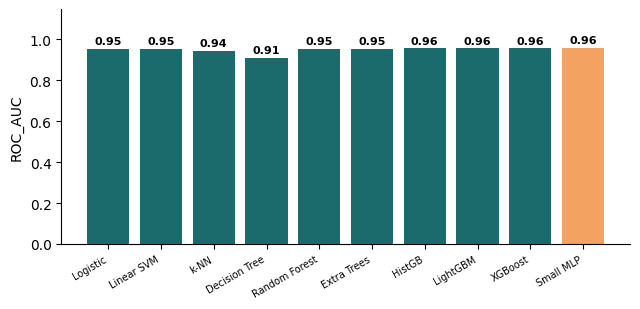

In [11]:
import matplotlib.pyplot as plt
def bar_chart(labels, values, ylabel, path, highlight=None, fmt='{:.1f}'):
    fig, ax = plt.subplots(figsize=(6.5, 3.2))
    colors = ['#F4A261' if i == highlight else '#1B6B6D' for i in range(len(values))]
    bars = ax.bar([str(l) for l in labels], values, color=colors)
    ax.bar_label(bars, labels=[fmt.format(v) for v in values], fontweight='bold', padding=2, fontsize=8 if len(values) > 7 else 10)
    ax.set_ylabel(ylabel); ax.set_ylim(0, max(values) * 1.2)
    ax.spines[['top', 'right']].set_visible(False)          # no top and right spines
    if len(values) > 7: ax.tick_params(axis='x', labelsize=7, rotation=30); plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout(); fig.savefig(path, dpi=300); plt.show()

bar_chart(res.model, res.iloc[:, 1], res.columns[1], 'report/fig_rq2_models.png', highlight=int(res.iloc[:, 1].idxmax()), fmt='{:.2f}')

## Cổng khả thi: có nên xoay câu hỏi không

- **Làm gì:** so mô hình tốt nhất với mốc đơn giản và in ra một trong ba kết luận.
- **Vì sao:** nếu mô hình không hơn mốc hoặc bài toán quá dễ, nhóm xoay câu hỏi ngay ở đây thay vì cố chỉnh mô hình. Xoay câu hỏi nghĩa là đổi điều được hỏi cho khớp với điều dữ liệu trả lời được, không phải chọn lại số liệu cho đẹp.

**Các hướng xoay của đề tài này:**

1. Nếu mô hình không hơn quy tắc "gần ngưỡng nhất": đổi RQ3 thành so quy tắc đơn giản với mô hình theo từng bang, và trình bày quy tắc như đề xuất thực dụng.
2. Nếu precision thấp ở mọi tầm: đổi mục tiêu từ "bắt đầu bùng phát" sang "còn bùng phát sau h tuần", là bài toán có tín hiệu mạnh hơn (ROC-AUC trên 0,95 trong lần chạy thử).
3. Nếu các tuần điền không làm lệch kết quả: thu hẹp về các bang có báo cáo đầy đủ và nêu rõ trong mục Data.

**Quyết định của nhóm (giữ câu hỏi hay xoay theo hướng nào, vì sao):** ...

In [12]:
best = res.sort_values('ROC_AUC').iloc[-1]; spread = res.ROC_AUC.max() - res.ROC_AUC.min()
print('best model %s: ROC-AUC %.4f, PR-AUC %.4f | spread between models %.4f' % (best.model, best.ROC_AUC, best.PR_AUC, spread))
verdict = 'TOO EASY: every model is near the ceiling, so the comparison says little; explain why the task is easy or use a harder protocol (RQ3)' if best.ROC_AUC >= 0.995 else 'GOOD: there is a clear signal and room to compare models' if best.ROC_AUC >= 0.75 else 'WEAK: the signal is weak, pivot the target or the features (see the options above) and report this result honestly'
print(verdict); pd.Series({'best_model': best.model, 'ROC_AUC': best.ROC_AUC, 'PR_AUC': best.PR_AUC, 'spread': spread, 'verdict': verdict}).to_csv('report/table_feasibility_gate.csv')

best model Small MLP: ROC-AUC 0.9572, PR-AUC 0.9626 | spread between models 0.0492
GOOD: there is a clear signal and room to compare models


## Bước 6b. Câu hỏi thứ ba (RQ3)

- **Làm gì:** Huấn luyện lại bốn mô hình đại diện cho từng tầm từ 1 đến 8 tuần và mười mô hình khi giữ riêng 30% đô thị.
- **Vì sao:** đây là đóng góp chính của bài; mỗi bảng `report/table_rq3_*.csv` ứng với một ý trong mục Results.
- **Kiểm tra:** đọc từng bảng in ra và viết một câu kết luận có số cho mỗi bảng. Nếu kết quả trái dự kiến trong đề cương thì báo đúng như vậy và tìm nguyên nhân, không chỉnh code cho ra kết quả mong muốn.

In [13]:
# Step 6b: RQ3, how many weeks ahead can the start of an outbreak be announced in the epidemic year, also for municipalities never seen?
calm = lambda d: d[d.above_now == 0]                    # an early warning matters where no outbreak is under way yet
def ece(y, p, bins=10):                                  # expected calibration error
    b = np.minimum((p * bins).astype(int), bins - 1); y = np.asarray(y)
    return sum((b == k).mean() * abs(y[b == k].mean() - p[b == k].mean()) for k in range(bins) if (b == k).any())
def alerts(d, p, share=0.10):                            # each week only the highest risks can be acted on: precision and recall of that list
    d = d.assign(p=p); d['rank'] = d.groupby('week_start').p.rank(ascending=False, method='first')
    k = d.groupby('week_start').p.transform('size') * share; hit = d['rank'] <= np.maximum(1, k)
    y = d['y']; return float(y[hit].mean()), float(y[hit].sum() / max(1, y.sum()))
FAM = ['Logistic', 'Random Forest', 'LightGBM', 'Small MLP']; rows = []
for h in range(1, 9):                                    # (1) lead-time curve, trained up to 2022 and frozen
    t = 'y%d' % h; B = calm(test).assign(y=calm(test)[t]); A = calm(train)
    pr, rc = alerts(B, (B.l0 - B.thr_log).to_numpy())                                   # simple rule: the municipalities closest to their threshold now
    rows.append([h, 'Rule: closest to threshold', np.nan, pr, rc, np.nan])
    for name in FAM:
        p = proba(models[name](0).fit(A[X_cols], A[t]), B[X_cols]); pr, rc = alerts(B, p)
        rows.append([h, name, roc_auc_score(B.y, p), pr, rc, ece(B.y, p)])
lead = pd.DataFrame(rows, columns=['weeks_ahead', 'model', 'ROC_AUC', 'precision_top10', 'recall_top10', 'ECE'])
lead.to_csv('report/table_rq3_lead_time.csv', index=False); print(lead.pivot(index='weeks_ahead', columns='model', values='precision_top10').round(3))
P_MIN = 0.35; ok = lead[lead.precision_top10 >= P_MIN].groupby('model').weeks_ahead.max()
ok.rename('longest_reliable_lead_weeks').to_csv('report/table_rq3_reliable_lead.csv'); print(ok)
# (2) municipalities never seen in training: 30% of them are held out completely
rng = np.random.RandomState(0); ids = feat.ibge.unique(); out = set(rng.choice(ids, int(0.3 * len(ids)), replace=False))
A = calm(part(2015, 2022)); A = A[~A.ibge.isin(out)]; A = A.sample(min(N_TRAIN, len(A)), random_state=0); T = calm(test); rows = []
for name, make in models.items():
    m = make(0).fit(A[X_cols], A[TARGET]); row = [name]
    for B in [T[~T.ibge.isin(out)], T[T.ibge.isin(out)]]:
        p = proba(m, B[X_cols]); row += [roc_auc_score(B[TARGET], p), alerts(B.assign(y=B[TARGET]), p)[0]]
    rows.append(row)
unseen = pd.DataFrame(rows, columns=['model', 'AUC_seen', 'precision_seen', 'AUC_unseen', 'precision_unseen'])
unseen['AUC_gap'] = unseen.AUC_seen - unseen.AUC_unseen; unseen.to_csv('report/table_rq3_unseen_municipalities.csv', index=False); print(unseen.round(3))

model        LightGBM  Logistic  Random Forest  Rule: closest to threshold  \
weeks_ahead                                                                  
1               0.362     0.385          0.358                       0.348   
2               0.363     0.392          0.345                       0.358   
3               0.313     0.342          0.310                       0.331   
4               0.342     0.348          0.329                       0.332   
5               0.323     0.371          0.320                       0.355   
6               0.335     0.364          0.329                       0.354   
7               0.314     0.344          0.313                       0.353   
8               0.306     0.355          0.298                       0.374   

model        Small MLP  
weeks_ahead             
1                0.384  
2                0.372  
3                0.335  
4                0.357  
5                0.358  
6                0.367  
7                0.

## Bước 6c. Kiểm tra bổ sung và bảng tham số

> Add blockquote



- **Làm gì:** chạy phép kiểm tra bổ sung của đề tài và lưu tham số mô hình.
- **Vì sao:** bảng này đi vào phần thảo luận và phụ lục của bài.
- **Kiểm tra:** `report/params_best.json` tồn tại.

In [14]:
# Step 6c: alert capacity, calibration from 2023 to 2024, the effect of zero-filled weeks, and parameters
best = res.sort_values('ROC_AUC').model.iloc[-1]; m = fitted[best]; rows = []
p24, p23 = proba(m, X_te), proba(m, calib[X_cols])
mc = models[best](0).fit(calm(train)[X_cols], calm(train)[TARGET]); Tc = calm(test); pc = proba(mc, Tc[X_cols])       # warning model for calm municipalities
for share in [0.05, 0.10, 0.20]:
    pr, rc = alerts(Tc.assign(y=Tc[TARGET]), pc, share); rows.append([share, pr, rc, float(Tc[TARGET].mean())])
cap = pd.DataFrame(rows, columns=['alert_share_per_week', 'precision', 'recall', 'base_rate']); cap.to_csv('report/table_rq3_capacity.csv', index=False); print(best); print(cap.round(3))
real = (test.filled == 0).to_numpy()
drift = pd.Series({'ECE_2023': ece(calib[TARGET], p23), 'ECE_2024': ece(y_te, p24), 'outbreak_share_2023': calib[TARGET].mean(), 'outbreak_share_2024': y_te.mean(),
                   'AUC_2024_all_weeks': roc_auc_score(y_te, p24), 'AUC_2024_reported_weeks_only': roc_auc_score(y_te[real], p24[real])})
drift.rename('value').to_csv('report/table_rq3_calibration_and_fill.csv'); print(drift.round(3))
by_state = test.assign(p=p24).groupby('state').apply(lambda g: pd.Series({'n': len(g), 'outbreak_share': g[TARGET].mean(),
           'AUC': roc_auc_score(g[TARGET], g.p) if g[TARGET].nunique() == 2 else np.nan})).sort_values('AUC')
by_state.to_csv('report/table_rq3_by_state.csv'); print(by_state.head(8).round(3))
import json
json.dump({'best': best, 'horizon_weeks': H0, 'P_MIN': P_MIN, 'municipalities': int(feat.ibge.nunique()),
           'params': {k: str(v) for k, v in models[best](0).get_params().items()}}, open('report/params_best.json', 'w'), indent=2)

Small MLP
   alert_share_per_week  precision  recall  base_rate
0                  0.05      0.402   0.156      0.121
1                  0.10      0.357   0.287      0.121
2                  0.20      0.293   0.479      0.121
ECE_2023                        0.034
ECE_2024                        0.037
outbreak_share_2023             0.337
outbreak_share_2024             0.510
AUC_2024_all_weeks              0.959
AUC_2024_reported_weeks_only    0.948
dtype: float64
                         n  outbreak_share    AUC
state                                            
SERGIPE               43.0           0.093  0.718
PARAIBA              258.0           0.264  0.843
ACRE                 129.0           0.163  0.858
PERNAMBUCO           903.0           0.241  0.875
RONDONIA              43.0           0.256  0.875
MARANHAO             129.0           0.240  0.895
RIO GRANDE DO SUL     43.0           0.605  0.921
RIO GRANDE DO NORTE  387.0           0.264  0.922


In [15]:

from sklearn.metrics import roc_auc_score
import numpy as np
import pandas as pd


def hit_weights(week, score, share=0.10):
    """Xếp hạng lại top share trong từng tuần.
    Các trường hợp đồng hạng tại vị trí cắt được chia đều số chỗ.
    """
    if not 0 < share <= 1:
        raise ValueError("share must be in (0, 1].")

    t = pd.DataFrame({"week": week, "score": score})
    g = t.groupby("week")["score"]

    rank_min = g.rank(
        ascending=False, method="min"
    ).to_numpy()

    rank_max = g.rank(
        ascending=False, method="max"
    ).to_numpy()

    n_week = g.transform("size").to_numpy()
    k = np.maximum(1, np.floor(n_week * share))

    weights = np.clip(
        (k - rank_min + 1) / (rank_max - rank_min + 1),
        0, 1
    )
    return weights


def prec_rec(y, alert_weights):
    """Precision và recall với trọng số cảnh báo."""
    tp = np.sum(alert_weights * y)
    n_alert = np.sum(alert_weights)
    n_positive = np.sum(y)

    precision = tp / n_alert if n_alert > 0 else np.nan
    recall = tp / n_positive if n_positive > 0 else np.nan

    return precision, recall


def boot_rerank(
    week, y, scores, municipality,
    B=1000, share=0.10, seed=0
):
    """Cluster bootstrap theo đô thị.
    Giữ toàn bộ chuỗi tuần của mỗi đô thị được lấy mẫu;
    xếp hạng lại danh sách cảnh báo trong mỗi mẫu.
    """
    week = np.asarray(week)
    y = np.asarray(y, dtype=float)
    municipality = np.asarray(municipality)

    ids = np.unique(municipality)
    rows_by_muni = [
        np.flatnonzero(municipality == m) for m in ids
    ]

    rng = np.random.RandomState(seed)
    out = {name: [] for name in scores}

    for _ in range(B):
        sampled_muni = rng.randint(0, len(ids), len(ids))

        # Mỗi lần chọn đô thị tạo ra một bản sao cụm riêng.
        sampled_rows = []
        sampled_week = []
        sampled_y = []

        for replicate_id, muni_idx in enumerate(sampled_muni):
            rows = rows_by_muni[muni_idx]
            sampled_rows.append(rows)

            # Tách tuần và bản sao để giữ đơn vị Bootstrap riêng.
            sampled_week.extend(
                [(week[i], replicate_id) for i in rows]
            )
            sampled_y.extend(y[rows])

        idx = np.concatenate(sampled_rows)
        yb = np.asarray(sampled_y, dtype=float)

        # Mỗi bản sao của đô thị là một đơn vị riêng.
        # Trong mỗi tuần, xếp hạng lại trên toàn bộ mẫu Bootstrap.
        wb = pd.MultiIndex.from_tuples(
            sampled_week, names=["week", "replicate"]
        ).get_level_values("week").to_numpy()

        # Điểm số được sao chép cùng với cụm tương ứng.
        for name, score in scores.items():
            sb = np.asarray(score)[idx]

            if np.unique(yb).size < 2:
                auc = np.nan
            else:
                auc = roc_auc_score(yb, sb)

            alert = hit_weights(wb, sb, share)
            precision, recall = prec_rec(yb, alert)

            out[name].append([auc, precision, recall])

    return {
        name: np.asarray(values, dtype=float)
        for name, values in out.items()
    }


## Bootstrap khoảng tin cậy theo đô thị cho AUC, precision, recall

In [16]:
# Việc 1 (bản sửa): bootstrap 95% theo ĐÔ THỊ, top 10% được XẾP HẠNG LẠI trong từng lượt bốc mẫu (tầm 4 tuần, đô thị đang yên ổn)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
B_REPS, SHARE, RULE = 1000, 0.10, 'Rule (gan nguong nhat)'
calm = lambda d: d[d.above_now == 0]

D = calm(test).copy().reset_index(drop=True); y = D[TARGET].to_numpy().astype(float); wk = D.week_start.factorize()[0]
A = calm(train)
scores = {RULE: (D.l0 - D.thr_log).to_numpy()}              # quy tắc: l0 - thr_log = ln((1+ca hiện tại)/(1+ngưỡng)), cùng thang log(1+x) với ngưỡng
for name in ['Logistic', 'Random Forest', 'LightGBM', 'Small MLP']:
    scores[name] = proba(models[name](0).fit(A[X_cols], A[TARGET]), D[X_cols])

NAMES = ['AUC', 'precision', 'recall']
point = {n: [roc_auc_score(y, s)] + list(prec_rec(y, hit_weights(wk, s, SHARE))) for n, s in scores.items()}
boot = boot_rerank(wk, y, scores, D.ibge.to_numpy(), B=B_REPS, share=SHARE)

rows = []                                                   # (1) khoảng tin cậy của từng mô hình
for n in scores:
    for j, m in enumerate(NAMES):
        lo, hi = np.percentile(boot[n][:, j], [2.5, 97.5]); rows.append([n, m, point[n][j], lo, hi])
ci = pd.DataFrame(rows, columns=['model', 'metric', 'estimate', 'ci_low', 'ci_high'])
ci.to_csv('report/table_rq3_bootstrap_ci.csv', index=False)
print(ci.assign(show=lambda t: t.estimate.round(3).astype(str) + '  [' + t.ci_low.round(3).astype(str) + ', ' + t.ci_high.round(3).astype(str) + ']')
        .pivot(index='model', columns='metric', values='show')[NAMES])

rows = []                                                   # (2) mô hình có thật sự hơn quy tắc đơn giản không?
for n in scores:
    if n == RULE: continue
    for j, m in enumerate(NAMES):
        lo, hi = np.percentile(boot[n][:, j] - boot[RULE][:, j], [2.5, 97.5])
        rows.append([n, m, point[n][j] - point[RULE][j], lo, hi, 'khac biet ro' if (lo > 0 or hi < 0) else 'chua khac biet'])
diff = pd.DataFrame(rows, columns=['model', 'metric', 'hon_quy_tac', 'ci_low', 'ci_high', 'ket_luan'])
diff.to_csv('report/table_rq3_bootstrap_vs_rule.csv', index=False); print(); print(diff.round(3).to_string(index=False))

metric                                    AUC              precision                 recall
model                                                                                      
LightGBM                0.847  [0.828, 0.866]  0.342  [0.303, 0.378]  0.276  [0.246, 0.306]
Logistic                  0.852  [0.83, 0.87]   0.348  [0.316, 0.39]   0.28  [0.253, 0.317]
Random Forest           0.837  [0.816, 0.856]  0.329  [0.295, 0.369]   0.265  [0.24, 0.296]
Rule (gan nguong nhat)   0.769  [0.746, 0.79]   0.332  [0.294, 0.37]  0.267  [0.237, 0.298]
Small MLP                0.862  [0.843, 0.88]  0.357  [0.315, 0.396]  0.287  [0.255, 0.317]

        model    metric  hon_quy_tac  ci_low  ci_high       ket_luan
     Logistic       AUC        0.083   0.063    0.104   khac biet ro
     Logistic precision        0.015  -0.010    0.051 chua khac biet
     Logistic    recall        0.012  -0.008    0.041 chua khac biet
Random Forest       AUC        0.068   0.047    0.090   khac biet ro
Random For

Precision top 10% theo tuần báo trước:
model        LightGBM  Logistic  Random Forest  Rule: closest to threshold  Small MLP
weeks_ahead                                                                          
1              0.3619    0.3852         0.3580                      0.3489     0.3839
2              0.3632    0.3917         0.3450                      0.3583     0.3722
3              0.3126    0.3424         0.3100                      0.3306     0.3346
4              0.3424    0.3476         0.3294                      0.3323     0.3567
5              0.3230    0.3709         0.3204                      0.3539     0.3580
6              0.3346    0.3645         0.3294                      0.3541     0.3671
7              0.3139    0.3437         0.3126                      0.3523     0.3476
8              0.3061    0.3554         0.2983                      0.3714     0.3307

Số tuần báo trước dài nhất (liên tục từ tuần 1):
precision_min               0.30  0.35  0.40
model 

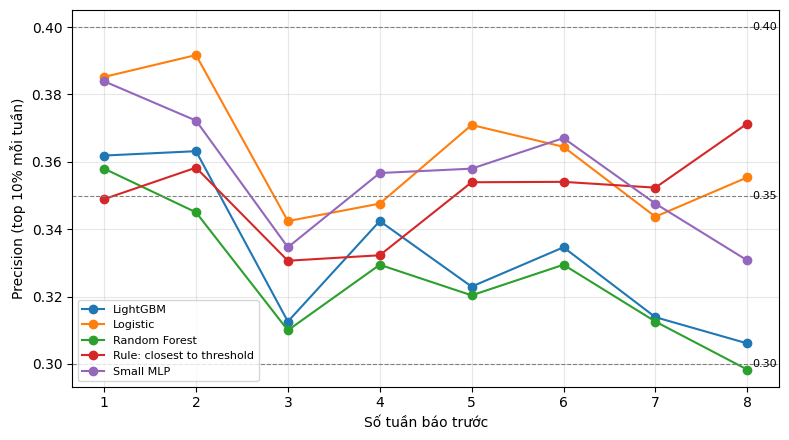

In [17]:
# Việc 2 (bản sửa): độ nhạy của ngưỡng "đáng tin"; precision của QUY TẮC được tính lại có xử lý điểm hòa
import matplotlib.pyplot as plt
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 20)
THRS = [0.30, 0.35, 0.40]
RULE_NAME = [m for m in lead.model.unique() if m.lower().startswith('rule')][0]
Dc = calm(test).copy().reset_index(drop=True); wk_c = Dc.week_start.factorize()[0]; w_rule = hit_weights(wk_c, (Dc.l0 - Dc.thr_log).to_numpy(), 0.10)
for h in range(1, 9):                                       # thay precision/recall của quy tắc bằng giá trị kỳ vọng khi bốc ngẫu nhiên các đô thị đồng hạng
    p_, r_ = prec_rec(Dc[f'y{h}'].to_numpy().astype(float), w_rule)
    lead.loc[(lead.model == RULE_NAME) & (lead.weeks_ahead == h), ['precision_top10', 'recall_top10']] = [p_, r_]
prec = lead.pivot(index='weeks_ahead', columns='model', values='precision_top10')      # hàng = số tuần báo trước, cột = mô hình

def longest(p, thr, consecutive):                          # p: precision theo số tuần báo trước (1..8)
    ok = (p >= thr).to_numpy()
    if consecutive:                                        # đạt ngưỡng liên tục từ tuần 1 trở đi
        h = 0
        for v in ok:
            if not v: break
            h += 1
        return h
    return int(p.index[ok].max()) if ok.any() else 0       # cách cũ: tuần xa nhất từng đạt ngưỡng, kể cả khi bị đứt quãng

rows = []
for thr in THRS:
    for name in prec.columns:
        rows.append([thr, name, longest(prec[name], thr, True), longest(prec[name], thr, False)])
sens = pd.DataFrame(rows, columns=['precision_min', 'model', 'lead_lien_tuc', 'lead_xa_nhat'])
sens.to_csv('report/table_rq3_threshold_sensitivity.csv', index=False)
print('Precision top 10% theo tuần báo trước:'); print(prec.round(4))
print('\nSố tuần báo trước dài nhất (liên tục từ tuần 1):')
print(sens.pivot(index='model', columns='precision_min', values='lead_lien_tuc'))
print('\nSố tuần báo trước xa nhất từng đạt ngưỡng (cách cũ):')
print(sens.pivot(index='model', columns='precision_min', values='lead_xa_nhat'))

fig, ax = plt.subplots(figsize=(8, 4.5))                    # hình: precision theo số tuần báo trước, kèm 3 ngưỡng
for name in prec.columns: ax.plot(prec.index, prec[name], marker='o', label=name)
for thr in THRS: ax.axhline(thr, color='gray', ls='--', lw=0.8); ax.text(8.05, thr, f'{thr:.2f}', va='center', fontsize=8)
ax.set_xlabel('Số tuần báo trước'); ax.set_ylabel('Precision (top 10% mỗi tuần)'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('report/fig_rq3_threshold.png', dpi=150); plt.show()


### Hình RQ3

- **Làm gì:** vẽ hai hình RQ3 từ các bảng `report/table_rq3_*.csv` bằng hàm `bar_chart` ở trên, theo mẫu Hình 4 và Hình 5 của đề cương.
- **Kiểm tra:** mỗi hình một ý, chữ tiếng Anh, số in đậm trên cột.

report/table_rq3_bootstrap_ci.csv (15, 5)
report/table_rq3_bootstrap_vs_rule.csv (12, 6)
report/table_rq3_by_state.csv (26, 4)
report/table_rq3_calibration_and_fill.csv (6, 2)


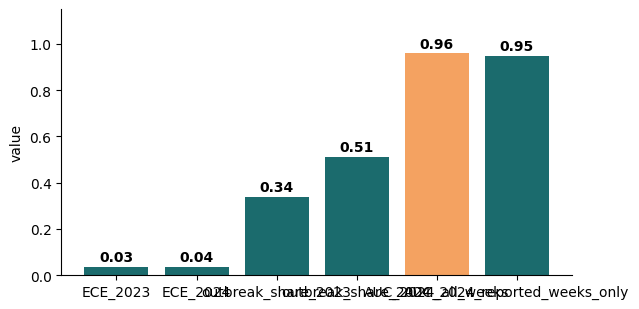

report/table_rq3_capacity.csv (3, 4)


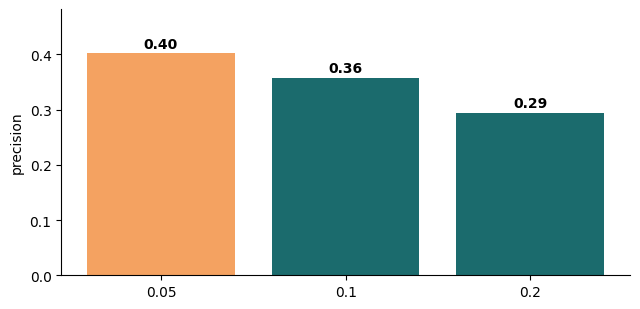

report/table_rq3_lead_time.csv (40, 6)
report/table_rq3_reliable_lead.csv (5, 2)


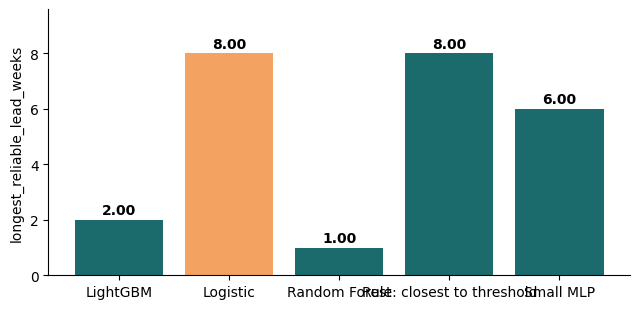

report/table_rq3_threshold_sensitivity.csv (15, 4)
report/table_rq3_unseen_municipalities.csv (10, 6)


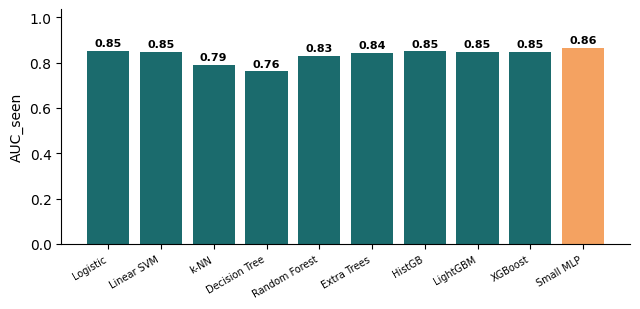

In [18]:
import glob
for f in sorted(glob.glob('report/table_rq3_*.csv')):
    t = pd.read_csv(f); numc = [c for c in t.columns[1:] if pd.api.types.is_numeric_dtype(t[c])]
    print(f, t.shape)
    if 2 <= len(t) <= 14 and numc and t[numc[0]].notna().all() and t[numc[0]].min() >= 0 and t[numc[0]].max() > 0:
        v, lab, fm = nice(t[numc[0]], numc[0]); bar_chart(t.iloc[:, 0].astype(str), v, lab, f.replace('table_', 'fig_').replace('.csv', '.png'), highlight=int(v.argmax()), fmt=fm)

## Test case và chẩn đoán

- **Làm gì:** kiểm tra tự động các sản phẩm của notebook.
- **Kiểm tra:** mọi `assert` qua. Sinh viên A chạy lại notebook này và ghi vào ô Đối chứng.

In [19]:
assert os.path.exists('report/table_rq2.csv') and os.path.exists('report/params_best.json')
assert len(glob.glob('report/table_rq3_*.csv')) >= 2, 'RQ3 tables missing'
assert res.iloc[:, 1].notna().all()
print(sorted(os.path.basename(f) for f in glob.glob('report/*')))
print('Notebook B: all checks passed')

['fig_rq2_models.png', 'fig_rq3_calibration_and_fill.png', 'fig_rq3_capacity.png', 'fig_rq3_reliable_lead.png', 'fig_rq3_threshold.png', 'fig_rq3_unseen_municipalities.png', 'params_best.json', 'table_feasibility_gate.csv', 'table_feature_strength.csv', 'table_rq2.csv', 'table_rq3_bootstrap_ci.csv', 'table_rq3_bootstrap_vs_rule.csv', 'table_rq3_by_state.csv', 'table_rq3_calibration_and_fill.csv', 'table_rq3_capacity.csv', 'table_rq3_lead_time.csv', 'table_rq3_reliable_lead.csv', 'table_rq3_threshold_sensitivity.csv', 'table_rq3_unseen_municipalities.csv', 'table_split_shift.csv']
Notebook B: all checks passed


### Đối chứng

| Người chạy lại | Ngày | Metric chính khớp | Ghi chú |
|---|---|---|---|
| | | | |

### Chẩn đoán

Nếu mô hình tốt nhất không hơn mốc đơn giản hoặc kết quả RQ3 trái dự kiến, ghi nguyên nhân có bằng chứng (thiếu đặc trưng, dữ liệu ít, lệch giữa hai tập) vào `report/table_diagnosis.csv`.

### Báo cáo tiến độ (dán vào kênh nhóm trước buổi báo cáo)

1. Việc đã xong, kèm tên file và số dòng, bảng, hình:
2. Con số chính mới có:
3. Vướng mắc và điều đã thử:
4. Việc sẽ làm đến lần báo cáo sau, ai làm:
5. Prompt AI đáng chú ý và Human Delta: